
# A decision support system designed to assist in the decision-making process for purchasing an apartment in Madrid
When someone wants to buy a flat they have a restricted budget, and consider different parameters.
In this code I will implement four parameters:

#### Facts

Location is Close with the probability of 40%.  
Location is Far with the probability of 60%.

Size is Large with the probability of 30%.
Size is Medium with the probability of 70%.  

The property has balcony with the probability of 50%. 

Swimming pool has a probability of 30% is the Location is Close.  
Swimming pool has a probability of 70% if the Location is Far.

Metro has a probability of 70% is the Location is Close.  
Metro has a probability of 30% if the Location is Far.

#### CPT table for number of rooms
| Size   | Number of Rooms (One) | Number of Rooms (Two) | Number of Rooms (More) |
|--------|------------------------|-----------------------|-------------------------|
| Large | 0.2                    | 0.3                   | 0.5                     |
| Medium  | 0.5                    | 0.3                   | 0.2                     |


### CPT table for condition of flat
| Location | Condition (New) | Condition (Good) | Condition (Bad) |
|----------|------------------|------------------|-----------------|
| Close    | 0.2              | 0.5              | 0.3             |
| Far      | 0.4              | 0.4              | 0.2             |


#### CPT table for dependent node Price:
| Condition | Location | Size   | Metro | Price (Affordable) | Price (Expensive) |
|-----------|----------|--------|-------|---------------------|--------------------|
| New       | Close    | Large  | Yes   | 0.1                 | 0.9                |
| New       | Close    | Large  | No    | 0.2                 | 0.8                |
| New       | Close    | Medium | Yes   | 0.3                 | 0.7                |
| New       | Close    | Medium | No    | 0.35                | 0.65               |
| New       | Far      | Large  | Yes   | 0.3                 | 0.7                |
| New       | Far      | Large  | No    | 0.4                 | 0.6                |
| New       | Far      | Medium | Yes   | 0.5                 | 0.5                |
| New       | Far      | Medium | No    | 0.6                 | 0.4                |
| Good      | Close    | Large  | Yes   | 0.2                 | 0.8                |
| Good      | Close    | Large  | No    | 0.3                 | 0.7                |
| Good      | Close    | Medium | Yes   | 0.3                 | 0.7                |
| Good      | Close    | Medium | No    | 0.4                 | 0.6                |
| Good      | Far      | Large  | Yes   | 0.3                 | 0.7                |
| Good      | Far      | Large  | No    | 0.4                 | 0.6                |
| Good      | Far      | Medium | Yes   | 0.5                 | 0.5                |
| Good      | Far      | Medium | No    | 0.6                 | 0.4                |
| Bad       | Close    | Large  | Yes   | 0.3                 | 0.7                |
| Bad       | Close    | Large  | No    | 0.4                 | 0.6                |
| Bad       | Close    | Medium | Yes   | 0.5                 | 0.5                |
| Bad       | Close    | Medium | No    | 0.6                 | 0.4                |
| Bad       | Far      | Large  | Yes   | 0.6                 | 0.4                |
| Bad       | Far      | Large  | No    | 0.7                 | 0.3                |
| Bad       | Far      | Medium | Yes   | 0.8                 | 0.2                |
| Bad       | Far      | Medium | No    | 0.9                 | 0.1                |


### Create model

In [1]:
import scipy
from scipy.sparse.csgraph import minimum_spanning_tree

In [2]:
from pgmpy.factors.discrete import TabularCPD

In [3]:
from pgmpy.models import BayesianNetwork

In [4]:
# Create the model by defining dependencies
real_estate_model = BayesianNetwork([
                              ('Location', 'Price'),
                              ('Size', 'Price'),
                              ('Condition', 'Price'),
                              ('Metro', 'Price'),
                              ('Location', 'Swimming Pool'),
                              ('Location', 'Metro'),
                              ('Location', 'Condition'),
                              ('Size', 'Number of Rooms')])

# Add Balcony as a standalone node
real_estate_model.add_node('Balcony')

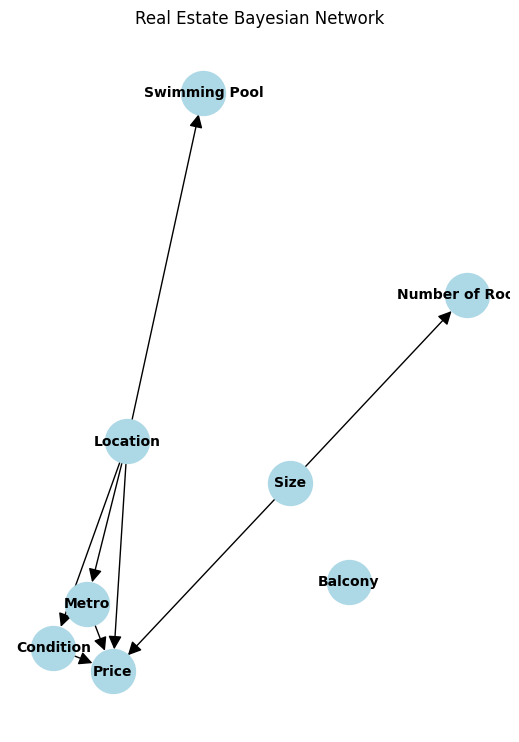

In [5]:
## Let's draw the graph to see if everything is correct!
import networkx as nx
from matplotlib import pyplot as plt
edges = real_estate_model.edges()
nodes = real_estate_model.nodes()

# Create a directed graph in NetworkX
G = nx.DiGraph()
G.add_nodes_from(nodes)
G.add_edges_from(edges)

# Draw the graph
plt.figure(figsize=(5, 7))
pos = nx.spring_layout(G, seed=45)
nx.draw(
    G, pos, with_labels=True, node_size=1000, node_color="lightblue",
    font_size=10, font_weight="bold", arrowsize=20
)

plt.title("Real Estate Bayesian Network")
plt.show()

### Add 8 CPD tables to the model

In [6]:
all_cpds = []
CPD_map = {}

In [7]:
location_cpd = TabularCPD(
    variable = 'Location',
    variable_card = 2,   # cardinality
    values = [[.4], [.6]])   # ['Close', 'Far']
all_cpds.append(location_cpd)
CPD_map['Close'] = 0
CPD_map['Far'] = 1

In [8]:
size_cpd = TabularCPD(
    variable = 'Size',
    variable_card = 2,   # cardinality
    values = [[.3], [.7]])   # ['Large', 'Medium']
all_cpds.append(size_cpd)
CPD_map['Large'] = 0
CPD_map['Medium'] = 1

In [9]:
balcony_cpd = TabularCPD(
    variable = 'Balcony',
    variable_card = 2,   # cardinality
    values = [[.5], [.5]])   # ['Yes', 'No']
all_cpds.append(balcony_cpd)
CPD_map['BYes'] = 0
CPD_map['BNo'] = 1

In [10]:
swimming_pool_cpd = TabularCPD(
    variable = 'Swimming Pool',
    variable_card = 2,
    values = [[.3, .7], # Yes
              [.7, .3]],# No
    evidence = ['Location'],
    evidence_card = [2])
all_cpds.append(swimming_pool_cpd)
CPD_map['SYes'] = 0
CPD_map['SNo'] = 1

In [11]:
metro_cpd = TabularCPD(
    variable = 'Metro',
    variable_card = 2,
    values = [[.7, .3], # Yes
              [.3, .7]],# No
    evidence = ['Location'],
    evidence_card = [2])
all_cpds.append(metro_cpd)
CPD_map['MYes'] = 0
CPD_map['MNo'] = 1

In [12]:
n_rooms_cpd = TabularCPD(
    variable = 'Number of Rooms',
    variable_card = 3,
    values = [[.2, .5], # One
              [.3, .3], # Two
              [.5, .2]], # More
    evidence = ['Size'],
    evidence_card = [2]) # Cardinalities of dependent nodes
all_cpds.append(n_rooms_cpd)
CPD_map['One'] = 0
CPD_map['Two'] = 1
CPD_map['More'] = 2

In [13]:
condition_cpd = TabularCPD(
    variable = 'Condition',
    variable_card = 3,
    values = [[.2, .4], # New
              [.5, .4], # Good
              [.3, .2]], # Bad
    evidence = ['Location'],
    evidence_card = [2])
all_cpds.append(condition_cpd)
CPD_map['New'] = 0
CPD_map['Good'] = 1
CPD_map['Bad'] = 2

In [14]:
price_cpd = TabularCPD(
    variable = 'Price',
    variable_card = 2,
    values = [[.1, .2, .3, .35, .3, .4, .5, .6, .2, .3, .3, .4, .3, .4, .5, .6, .3, .4, .5, .6, .6, .7, .8, .9], # Affordable
              [.9, .8, .7, .65, .7, .6, .5, .4, .8, .7, .7, .6, .7, .6, .5, .4, .7, .6, .5, .4, .4, .3, .2, .1]], # Expensive
    evidence = ['Condition', 'Location', 'Size', 'Metro'],
    evidence_card = [3,2,2,2])
all_cpds.append(price_cpd)
CPD_map['Affordable'] = 0
CPD_map['Expensive'] = 1

In [15]:
# Add CPDs to the model
# real_estate_model.remove_cpds(*real_estate_model.cpds)
real_estate_model.add_cpds(*all_cpds)

### Check nodes and dependencies

In [16]:
## Check CPDs and dependencies
real_estate_model.get_cpds()

[<TabularCPD representing P(Location:2) at 0x262276135f0>,
 <TabularCPD representing P(Size:2) at 0x2622a1afe30>,
 <TabularCPD representing P(Balcony:2) at 0x2622a1c44d0>,
 <TabularCPD representing P(Swimming Pool:2 | Location:2) at 0x2622817d940>,
 <TabularCPD representing P(Metro:2 | Location:2) at 0x2622a1bd940>,
 <TabularCPD representing P(Number of Rooms:3 | Size:2) at 0x2622a1bd160>,
 <TabularCPD representing P(Condition:3 | Location:2) at 0x2622a1be450>,
 <TabularCPD representing P(Price:2 | Condition:3, Location:2, Size:2, Metro:2) at 0x2622a1bc620>]

The 8 nodes and their dependencies look correct

In [31]:
# List all global independencies in the model
# real_estate_model.get_independencies()

In [18]:
# We can check local independencies for specific node
real_estate_model.local_independencies('Location')

(Location ⟂ Balcony, Number of Rooms, Size)

In [19]:
# Neigbours and condition variables -> probabistically dependend nodes
real_estate_model.active_trail_nodes('Location')

{'Location': {'Condition', 'Location', 'Metro', 'Price', 'Swimming Pool'}}

In [20]:
real_estate_model.active_trail_nodes('Price')

{'Price': {'Condition',
  'Location',
  'Metro',
  'Number of Rooms',
  'Price',
  'Size',
  'Swimming Pool'}}

(Bonus task)
With this we could verify dependency between Price and Number of Rooms.
We will see later if changing its values really changes the results for Price

### Get Probability answers from the model

In [21]:
from pgmpy.inference import VariableElimination

In [22]:
real_estate_inference = VariableElimination(real_estate_model)

### Query questions

In [23]:
# What is the probable budget needed for medium-size properties that are in the centre, close to a metro station, and has balcony?
# Does it have a Swimming Pool?
# Price(0): Affordable
# Price(1): Expensive

try:
    prob_price_Close_MediumSize_Metro_Balcony = real_estate_inference.query(
            variables = ['Price', 'Swimming Pool'], joint=False,
            evidence = {'Location': CPD_map['Close'], 'Size': CPD_map['Medium'], 'Metro': CPD_map['MYes'], 'Balcony': CPD_map['BYes']})
    
    print(prob_price_Close_MediumSize_Metro_Balcony['Price'])
    print(prob_price_Close_MediumSize_Metro_Balcony['Swimming Pool'])
except Exception as e:
    print(f"Error during the query:{e}")

+----------+--------------+
| Price    |   phi(Price) |
+==========+==============+
| Price(0) |       0.3600 |
+----------+--------------+
| Price(1) |       0.6400 |
+----------+--------------+
+------------------+----------------------+
| Swimming Pool    |   phi(Swimming Pool) |
+==================+======================+
| Swimming Pool(0) |               0.3000 |
+------------------+----------------------+
| Swimming Pool(1) |               0.7000 |
+------------------+----------------------+


With 64% probability we will need more than 300.000 EUR, and it most likely (30%) don't have a swimming pool.

In [30]:
# How likely is that we find a new large flat for less than 300.000 EUR in the city centre which has 4 rooms?
# Condition(0): New
try:
    prob_condition_Affordable_Big_Centre_4_rooms = real_estate_inference.query(
            variables = ['Condition', ], joint=False,
            evidence = {'Price': CPD_map['Affordable'], 'Location': CPD_map['Close'], 'Size': CPD_map['Large'], 'Number of Rooms': CPD_map['More'] })
    print(prob_condition_Affordable_Big_Centre_4_rooms['Condition'])

except Exception as e:
    print(f"Error during the query:{e}")

+--------------+------------------+
| Condition    |   phi(Condition) |
+==============+==================+
| Condition(0) |           0.1083 |
+--------------+------------------+
| Condition(1) |           0.4792 |
+--------------+------------------+
| Condition(2) |           0.4125 |
+--------------+------------------+


It's not likely that we will find a new flat with the given criterium (11%)

In [25]:
# How many rooms may a flat have which is in the city centre, affordable, and not in bad condition?
# For this, I will query for Good and New conditions, and add their probabilities

try:
    prob_rooms_centre_affordable_new = real_estate_inference.query(
            variables = ['Number of Rooms'], joint=False,
            evidence = {'Location': CPD_map['Close'], 'Price': CPD_map['Affordable'], 'Condition': CPD_map['New']})
    
    prob_rooms_centre_affordable_good = real_estate_inference.query(
            variables = ['Number of Rooms'], joint=False,
            evidence = {'Location': CPD_map['Close'], 'Price': CPD_map['Affordable'], 'Condition': CPD_map['Good']})
    
    prob_new_or_good = prob_rooms_centre_affordable_new['Number of Rooms'] + prob_rooms_centre_affordable_good['Number of Rooms']
    
    print(prob_new_or_good)
except Exception as e:
    print(f"Error during the query:{e}")

+--------------------+------------------------+
| Number of Rooms    |   phi(Number of Rooms) |
+====================+========================+
| Number of Rooms(0) |                 0.8859 |
+--------------------+------------------------+
| Number of Rooms(1) |                 0.6000 |
+--------------------+------------------------+
| Number of Rooms(2) |                 0.5141 |
+--------------------+------------------------+


It will most likely has only one room (89%), but there is a good chance that it will has two (60%) or even more (51%) rooms

### Estimate causal effect of different variables on a selected node

In [26]:
from pgmpy.inference.CausalInference import CausalInference
cif = CausalInference(real_estate_model)

try:
    # Querying the causal effect of setting Metro to "No" on the probability of Price
    effect_metro = cif.query(
        variables=['Price'], 
        do={'Metro': CPD_map["MNo"]})
    print("Causal Effect of Metro on Price:")
    print(effect_metro)

    # Querying the causal effect of setting Location to "Close" on the probability of Price
    effect_location = cif.query(
        variables=['Price'], 
        do={'Location': CPD_map["Close"] })
    print("\nCausal Effect of Location on Price:")
    print(effect_location)

    # Querying the causal effect of setting Condition to "Bad" on the probability of Price
    effect_condition = cif.query(
        variables=['Price'], 
        do={'Condition': CPD_map["Bad"] })
    print("\nCausal Effect of Condition on Price:")
    print(effect_condition)

except Exception as e:
    print(f"Error during the query:{e}")

  0%|          | 0/2 [00:00<?, ?it/s]

Causal Effect of Metro on Price:
+----------+--------------+
| Price    |   phi(Price) |
+==========+==============+
| Price(0) |       0.5232 |
+----------+--------------+
| Price(1) |       0.4768 |
+----------+--------------+

Causal Effect of Location on Price:
+----------+--------------+
| Price    |   phi(Price) |
+==========+==============+
| Price(0) |       0.3429 |
+----------+--------------+
| Price(1) |       0.6571 |
+----------+--------------+


  0%|          | 0/2 [00:00<?, ?it/s]


Causal Effect of Condition on Price:
+----------+--------------+
| Price    |   phi(Price) |
+==========+==============+
| Price(0) |       0.6740 |
+----------+--------------+
| Price(1) |       0.3260 |
+----------+--------------+


### Perform interventions and assess the changes

In [27]:
# Query the original probabilities of Price based on the current network setup, without any interventions
try:
    price = cif.query(variables = ['Price'])
    print("Probabilites of Price before any intervention:")
    print(price)
except Exception as e:
    print(f"Error during the query:{e}")
    
# Query the probabilities of Price after setting Location to Far,
# isolating the causal effect of Location = Far on Price
try:
    price_location_far = cif.query(
        variables = ['Price'],
        do = {'Location': CPD_map['Far']}
    )
    print("\nProbabilities after Location is set to Far:")
    print(price_location_far)
except Exception as e:
    print(f"Error during the query:{e}")

Probabilites of Price before any intervention:
+----------+--------------+
| Price    |   phi(Price) |
+==========+==============+
| Price(0) |       0.4792 |
+----------+--------------+
| Price(1) |       0.5208 |
+----------+--------------+

Probabilities after Location is set to Far:
+----------+--------------+
| Price    |   phi(Price) |
+==========+==============+
| Price(0) |       0.5700 |
+----------+--------------+
| Price(1) |       0.4300 |
+----------+--------------+


In [29]:
print("Probabilites of Price before any intervention:")
print(price)

# Query the probabilities of Price after setting Condition to Bad, 
# isolating the causal effect of Condition = Bad on Price
try:
    price_location_far = cif.query(
    variables = ['Price'],
    do = {'Condition': CPD_map['Bad']}
    )
    print("\nProbabilities after Condition is set to Bad:")
    print(price_location_far)
except Exception as e:
    print(f"Error during the query:{e}")

Probabilites of Price before any intervention:
+----------+--------------+
| Price    |   phi(Price) |
+==========+==============+
| Price(0) |       0.4792 |
+----------+--------------+
| Price(1) |       0.5208 |
+----------+--------------+


  0%|          | 0/2 [00:00<?, ?it/s]


Probabilities after Condition is set to Bad:
+----------+--------------+
| Price    |   phi(Price) |
+==========+==============+
| Price(0) |       0.6740 |
+----------+--------------+
| Price(1) |       0.3260 |
+----------+--------------+
